EDA - STUDENT PERFORMANCE ANALYSIS

First five rows:
   Student_ID  Study_Hours  Attendance  Previous_Score  Sleep_Hours  \
0           1          3.6        90.4            95.8          6.3   
1           2          7.7        94.8            96.8          7.9   
2           3          6.1        65.9            94.0          6.7   
3           4          5.2        55.5            55.9          7.3   
4           5          2.1        61.4            31.1          NaN   

   Final_Score  
0         89.1  
1        100.0  
2         99.2  
3         64.3  
4         61.1  

Dataset Shape: (121, 6)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Student_ID      121 non-null    int64  
 1   Study_Hours     121 non-null    float64
 2   Attendance      120 non-null    float64
 3   Previous_Score  121 non-null    float64
 4   Sle

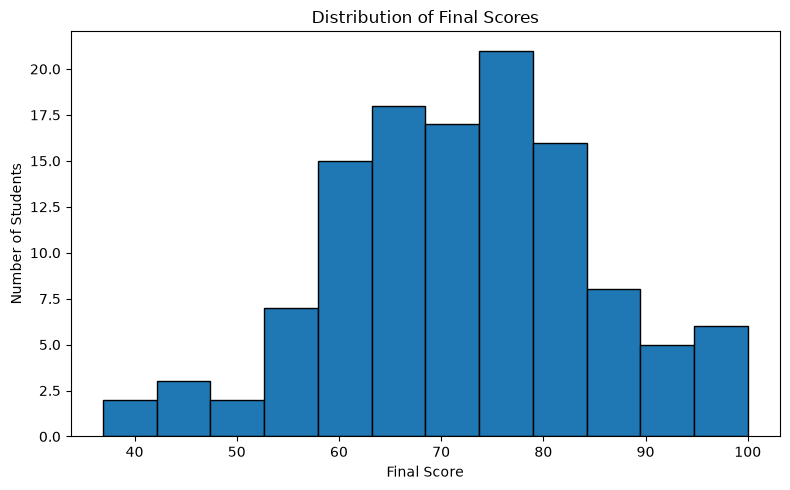

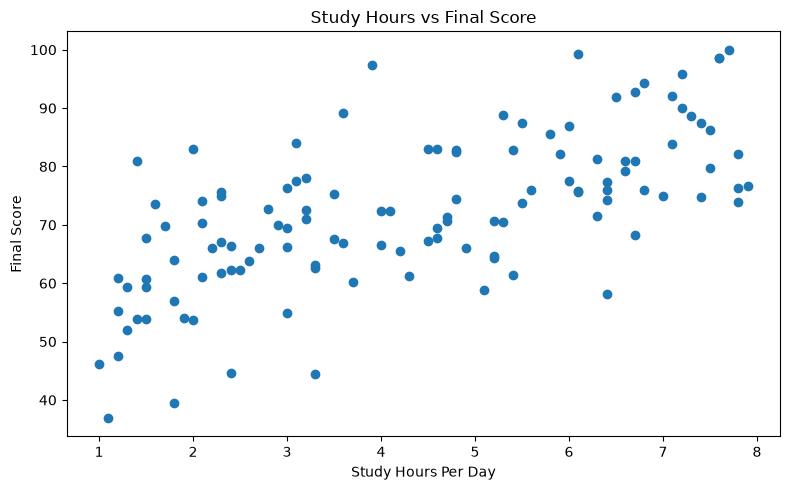

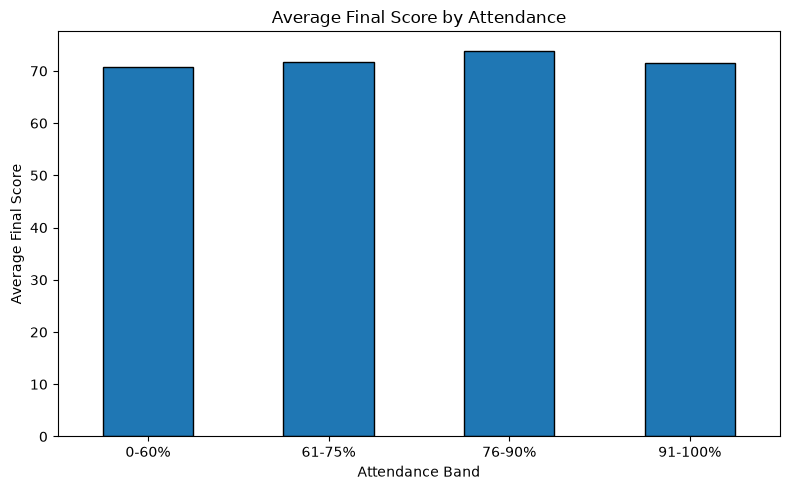

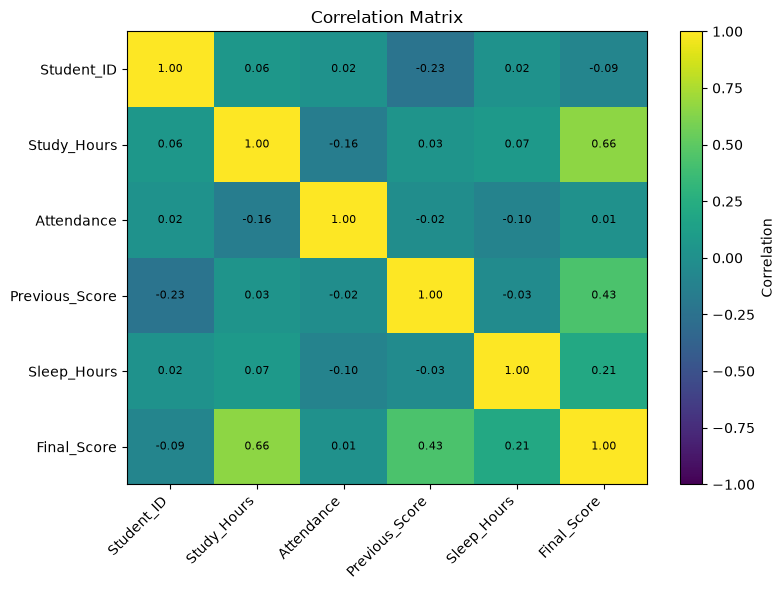


KEY STATISTICS
Mean Final Score: 72.21
Median Final Score: 72.45
Minimum Final Score: 36.9
Maximum Final Score: 100.0
Standard Deviation: 13.04
Study Hours / Final Score Correlation: 0.663

OBSERVATIONS
1. The histogram shows the distribution of student final scores.
2. The scatter plot helps identify the relationship between study hours and scores.
3. Attendance groups can be compared using their average final scores.
4. The correlation matrix summarizes relationships among numeric variables.
5. Missing numeric values are filled using the median, and duplicate rows are removed.

EDA TASK COMPLETED SUCCESSFULLY!
Check the eda_outputs folder for charts and the cleaned CSV.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Create output folder
output_dir = Path("eda_outputs")
output_dir.mkdir(exist_ok=True)

# --------------------------------------------------
# 1. CREATE SAMPLE STUDENT PERFORMANCE DATASET
# --------------------------------------------------

np.random.seed(42)
n = 120

data = {
    "Student_ID": range(1, n + 1),
    "Study_Hours": np.random.uniform(1, 8, n).round(1),
    "Attendance": np.random.uniform(50, 100, n).round(1),
    "Previous_Score": np.random.uniform(30, 100, n).round(1),
    "Sleep_Hours": np.random.uniform(4, 10, n).round(1)
}

df = pd.DataFrame(data)

df["Final_Score"] = (
    15
    + df["Study_Hours"] * 4
    + df["Attendance"] * 0.2
    + df["Previous_Score"] * 0.25
    + df["Sleep_Hours"] * 1.2
    + np.random.normal(0, 7, n)
).clip(0, 100).round(1)

# Add missing values and a duplicate for cleaning practice
df.loc[4, "Sleep_Hours"] = np.nan
df.loc[13, "Attendance"] = np.nan
df = pd.concat([df, df.iloc[[0]]], ignore_index=True)

print("EDA - STUDENT PERFORMANCE ANALYSIS")
print("\nFirst five rows:")
print(df.head())

# --------------------------------------------------
# 2. DATASET INFORMATION
# --------------------------------------------------

print("\nDataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

# --------------------------------------------------
# 3. CHECK MISSING VALUES AND DUPLICATES
# --------------------------------------------------

print("\nMissing Values Before Cleaning:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

# --------------------------------------------------
# 4. DATA CLEANING
# --------------------------------------------------

df = df.drop_duplicates().copy()

numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nDuplicate Rows After Cleaning:", df.duplicated().sum())

df.to_csv(output_dir / "cleaned_student_performance.csv",
          index=False)

print("\nCleaned dataset saved successfully.")

# --------------------------------------------------
# 5. VISUALIZATION 1: SCORE DISTRIBUTION
# --------------------------------------------------

plt.figure(figsize=(8, 5))
plt.hist(df["Final_Score"], bins=12, edgecolor="black")
plt.title("Distribution of Final Scores")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.savefig(output_dir / "01_score_distribution.png")
plt.show()
plt.close()

# --------------------------------------------------
# 6. VISUALIZATION 2: STUDY HOURS VS FINAL SCORE
# --------------------------------------------------

plt.figure(figsize=(8, 5))
plt.scatter(df["Study_Hours"], df["Final_Score"])
plt.title("Study Hours vs Final Score")
plt.xlabel("Study Hours Per Day")
plt.ylabel("Final Score")
plt.tight_layout()
plt.savefig(output_dir / "02_study_hours_vs_score.png")
plt.show()
plt.close()

# --------------------------------------------------
# 7. VISUALIZATION 3: ATTENDANCE VS SCORE
# --------------------------------------------------

attendance_bins = [0, 60, 75, 90, 100]
attendance_labels = [
    "0-60%", "61-75%", "76-90%", "91-100%"
]

df["Attendance_Band"] = pd.cut(
    df["Attendance"],
    bins=attendance_bins,
    labels=attendance_labels,
    include_lowest=True
)

average_scores = df.groupby(
    "Attendance_Band", observed=False
)["Final_Score"].mean()

plt.figure(figsize=(8, 5))
average_scores.plot(kind="bar", edgecolor="black")
plt.title("Average Final Score by Attendance")
plt.xlabel("Attendance Band")
plt.ylabel("Average Final Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(output_dir / "03_attendance_vs_score.png")
plt.show()
plt.close()

# --------------------------------------------------
# 8. VISUALIZATION 4: CORRELATION MATRIX
# --------------------------------------------------

numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.corr()

plt.figure(figsize=(8, 6))
plt.imshow(correlation, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)
plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(
            j, i, f"{correlation.iloc[i, j]:.2f}",
            ha="center", va="center", fontsize=8
        )

plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig(output_dir / "04_correlation_matrix.png")
plt.show()
plt.close()

# --------------------------------------------------
# 9. STATISTICAL ANALYSIS
# --------------------------------------------------

print("\nKEY STATISTICS")

print("Mean Final Score:",
      round(df["Final_Score"].mean(), 2))

print("Median Final Score:",
      round(df["Final_Score"].median(), 2))

print("Minimum Final Score:",
      df["Final_Score"].min())

print("Maximum Final Score:",
      df["Final_Score"].max())

print("Standard Deviation:",
      round(df["Final_Score"].std(), 2))

print("Study Hours / Final Score Correlation:",
      round(df["Study_Hours"].corr(df["Final_Score"]), 3))

# --------------------------------------------------
# 10. OBSERVATIONS
# --------------------------------------------------

observations = [
    "The histogram shows the distribution of student final scores.",
    "The scatter plot helps identify the relationship between study hours and scores.",
    "Attendance groups can be compared using their average final scores.",
    "The correlation matrix summarizes relationships among numeric variables.",
    "Missing numeric values are filled using the median, and duplicate rows are removed."
]

print("\nOBSERVATIONS")

for number, observation in enumerate(observations, start=1):
    print(f"{number}. {observation}")

with open(output_dir / "observations.txt", "w", encoding="utf-8") as file:
    for number, observation in enumerate(observations, start=1):
        file.write(f"{number}. {observation}\n")

print("\nEDA TASK COMPLETED SUCCESSFULLY!")
print("Check the eda_outputs folder for charts and the cleaned CSV.")